# 04 - EMT-TF Expression (unconditional final step)
Score EMT transcription factors gated on **detectable expression** (>=3% of cells), across the
Snail / Zeb / Twist **and** FOXC / PRRX mesenchymal families (VIM excluded - it is a marker, not
a TF). Overlay the two most informative factors as thresholded expressers (categorical) on the
grey manifold, in the house linear layout.

In [ ]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, matplotlib.pyplot as plt
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [ ]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*4))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
os.makedirs(pth_fig, exist_ok=True)

In [ ]:
# load signatures h5ad, use house linear layout
adata = sc.read_h5ad(os.path.join(pth_out, 'signatures.h5ad'))
adata.obsm['X_umap'] = adata.obsm['X_umap_lin']
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('cells:', adata.shape[0], '| pseudotime range', round(t.min(),2), '->', round(t.max(),2))

cells: 1435 | pseudotime range 0.0 -> 10.71


In [ ]:
# EMT-TF panel: Snail/Zeb/Twist + FOXC/PRRX; detection-gated (3% floor); VIM excluded
panel = ['SNAI1','SNAI2','ZEB1','ZEB2','TWIST1','TWIST2','FOXC1','FOXC2','PRRX1','PRRX2']
present = [g for g in panel if g in adata.var_names]
early = tn <= np.quantile(tn, 1/3); late = tn >= np.quantile(tn, 2/3)
X = adata[:,present].X; X = X.toarray() if hasattr(X,'toarray') else np.asarray(X)
rows = []
for j,g in enumerate(present):
    x = X[:,j]; expr = x > 0
    rho,p = spearmanr(tn, x)
    rows.append((g, round(expr.mean(),3), round(x[early].mean(),3),
                 round(x[late].mean(),3), round(rho,3)))
df = pd.DataFrame(rows, columns=['TF','frac_expr','mean_early','mean_late','rho_vs_t'])
df['end'] = np.where(df.mean_early > df.mean_late, 'EARLY(root)', 'LATE(terminus)')
df = df.sort_values('rho_vs_t')
print('panel genes present:', present, '| absent:', [g for g in panel if g not in present])
print(df.to_string(index=False))
ok = df[df.frac_expr > 0.03]
early_tf = ok.sort_values('rho_vs_t').iloc[0]['TF']
late_tf  = ok.sort_values('rho_vs_t').iloc[-1]['TF']
print(f'\nfactors above 3% detection floor: {sorted(ok.TF.tolist())}')
print(f'derived pair: {early_tf} (early/root) <-> {late_tf} (late/terminus) by rho ranking')

panel genes present: ['SNAI1', 'SNAI2', 'ZEB1', 'ZEB2', 'FOXC1', 'FOXC2', 'PRRX2'] | absent: ['TWIST1', 'TWIST2', 'PRRX1']
   TF  frac_expr  mean_early  mean_late  rho_vs_t            end
 ZEB2      0.233       0.051      0.049    -0.200    EARLY(root)
SNAI1      0.006       0.001      0.000    -0.071    EARLY(root)
 ZEB1      0.031       0.006      0.006    -0.033 LATE(terminus)
FOXC2      0.055       0.005      0.017     0.017 LATE(terminus)
PRRX2      0.003       0.000      0.000     0.018 LATE(terminus)
SNAI2      0.003       0.000      0.000     0.019 LATE(terminus)
FOXC1      0.036       0.001      0.022     0.031 LATE(terminus)

factors above 3% detection floor: ['FOXC1', 'FOXC2', 'ZEB1', 'ZEB2']
derived pair: ZEB2 (early/root) <-> FOXC1 (late/terminus) by rho ranking


overlay thresholds (upper quartile among expressers): {'ZEB2': 0.287, 'FOXC1': 0.475} | cells shown: {'ZEB2': 84, 'FOXC1': 13}
ZEB2: 23.3% expressing; 84 shown (upper quartile), mean pseudotime of shown cells = 0.43 (all cells = 0.43)
FOXC1: 3.6% expressing; 13 shown (upper quartile), mean pseudotime of shown cells = 0.70 (all cells = 0.43)
shown-cell pseudotime separation (ZEB2 vs FOXC1) = 0.27
saved expression.pdf


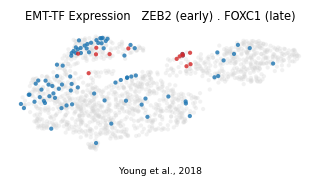

In [ ]:
# categorical overlay: thresholded expressers (upper quartile among expressers) on grey manifold
xl = adata.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
def _vec(g):
    x = adata[:,g].X
    return x.toarray().ravel() if hasattr(x,'toarray') else np.asarray(x).ravel()
thr = {}
for g in [early_tf, late_tf]:
    v = _vec(g); pos = v[v>0]; thr[g] = float(np.quantile(pos, 0.75)) if pos.size else 0.0
sel = {g: _vec(g) > thr[g] for g in [early_tf, late_tf]}
print('overlay thresholds (upper quartile among expressers):', {g: round(thr[g],3) for g in [early_tf, late_tf]},
      '| cells shown:', {g: int(sel[g].sum()) for g in [early_tf, late_tf]})
order = sorted([early_tf, late_tf], key=lambda g: -int(sel[g].sum()))
colors = {early_tf:'tab:blue', late_tf:'tab:red'}
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(adata, size=30, alpha=.3, frameon=False, show=False, ax=ax, na_color='lightgray')
for g in order:
    ap = adata[sel[g]].copy()
    sc.pl.umap(ap, na_color=colors[g], size=30, alpha=.8, frameon=False, show=False, ax=ax)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.set_title(f'EMT-TF Expression   {early_tf} (early) . {late_tf} (late)', size=7.5)
ax.text(.5,-.14,'Young et al., 2018', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'expression.pdf'), bbox_inches='tight')
for g in [early_tf, late_tf]:
    m = sel[g]
    print(f'{g}: {(_vec(g)>0).mean()*100:.1f}% expressing; {int(m.sum())} shown (upper quartile), '
          f'mean pseudotime of shown cells = {tn[m].mean():.2f} (all cells = {tn.mean():.2f})')
sep = abs(tn[sel[late_tf]].mean() - tn[sel[early_tf]].mean())
print(f'shown-cell pseudotime separation ({early_tf} vs {late_tf}) = {sep:.2f}')
print('saved expression.pdf')